# Stage 01 — Text Dataset Audit and Exploratory Analysis

## Objective

Characterize **E-commerce Text Classification** before selecting preprocessing operations.
Each row contains a product description (`text`, input) and one of four product categories
(`label`, target): Household, Books, Clothing & Accessories, Electronics. The intended
application is assigning a product category from its description, rather than sentiment analysis.

Use the [original Kaggle CSV](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification),
with provenance in [Gautam's Zenodo record](https://zenodo.org/records/3355823)
([DOI](https://doi.org/10.5281/zenodo.3355823), version 2, CC BY 4.0).
The source describes scraping an Indian e-commerce platform; representativeness of other
markets/languages is unverified. The [assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
requires at least 10,000 texts, at least two labels, length analysis with Mann–Whitney U,
class word clouds/top-50, TTR and Zipf analysis. The measured eligibility appears below.

This chapter completes **Part B Stage 01 only**. It does not select a best cleaning method,
train a classifier, export a split or implement the later tokenization/representation benchmarks.

## Methodology

1. Audit the headerless CSV, source hashes, missingness, label balance, exact/canonical
   duplicates and potentially meaningful surface patterns. Preserve the raw file and frame.
2. Describe raw character and whitespace-word lengths in a nonempty, valid-label view.
   Compare all six unordered label pairs for each of two metrics with two-sided
   Mann–Whitney U (asymptotic, tie correction and continuity correction). Holm adjustment
   controls a **family of 12 comparisons** at α=0.05 under the working test assumptions.
   Repeat a separate 12-test sensitivity family after keeping the first exact text only.
3. Count lexical tokens in a clearly marked lowercase descriptive view. Keep stopwords,
   retain digits, and use the same frequency dictionaries for word clouds and top-50 tables.
   Report corpus/class TTR and equal-token-budget repeated sampling with seed 42.
4. Describe rank–frequency behavior on log–log axes, including slope −1 as a reference.
   A log-linear fit is a descriptive summary, not a test proving a power law.

Mann–Whitney concerns distributions/probability ordering; it is not specifically a median
test without additional common-shape/location-shift assumptions. Report medians as practical
summaries and signed rank-biserial effect size $r_{rb}=2U/(n_A n_B)-1$ (positive: A tends
longer). Ties contribute half to the underlying probability of superiority. Duplicates and
product variants weaken independence; even deduplicated p-values are **not claimed to be
fully calibrated**. No downstream choice is based on significance alone.

All rows and labels are exposed to EDA. Any later holdout drawn from this corpus must be
called an **internal post-EDA assessment**, never an unobserved external test.

## Implementation

Run all cells in a fresh project `.venv` kernel (`hcmus-wids`). Root discovery works from
repository root or `book/text/`. Preparation downloads only if the CSV is absent, reuses
an existing ZIP, and opens the destination exclusively so an existing CSV is never replaced.
Kaggle authentication stays outside the repository. Static HTML uses saved outputs and does
not execute this download or require the CSV.

In [1]:
from pathlib import Path
from collections import Counter
from itertools import combinations, islice
from importlib.metadata import version
import hashlib
import html
import platform
import re
import shutil
import subprocess
import sys
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from wordcloud import WordCloud
from IPython.display import display, HTML

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "myst.yml").is_file() and (p / "src/text_data.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside this repository.")
if Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    raise RuntimeError("Select the project .venv kernel (hcmus-wids), restart and Run All.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.text_data import LABELS, read_ecommerce, canonical_key, duplicate_groups

DATA_PATH = ROOT / "data/raw/ecommerce/ecommerceDataset.csv"
SEED, ALPHA = 42, 0.05
COLORS = dict(zip(LABELS, sns.color_palette("colorblind", 4)))
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140})
pd.set_option("display.max_columns", 20)

def prose(text):
    # MyST reliably renders HTML display outputs; escape data before adding emphasis.
    safe = html.escape(text)
    return HTML("<p>" + re.sub(r"\*\*(.+?)\*\*", r"<strong>\1</strong>", safe) + "</p>")

def show_table(frame, title=None, collapse=False, **kwargs):
    # All dataset strings are escaped by pandas; no raw HTML from a description is rendered.
    body = '<div style="overflow-x:auto">' + frame.to_html(escape=True, **kwargs) + '</div>'
    if collapse:
        body = f"<details><summary>{html.escape(title or 'Supporting table')}</summary>{body}</details>"
    elif title:
        body = f"<p><strong>{html.escape(title)}</strong></p>" + body
    display(HTML(body))

print("Python", platform.python_version(), "| Project .venv verified")
show_table(pd.DataFrame({"package": ["numpy", "pandas", "scipy", "statsmodels", "wordcloud"],
                         "version": [version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "wordcloud"]]}), index=False)

Python 3.13.3 | Project .venv verified


package,version
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
statsmodels,0.15.0
wordcloud,1.9.6


In [2]:
DOWNLOAD_IF_MISSING = True
preparation = "existing CSV; no download/replacement"
if not DATA_PATH.is_file() and DOWNLOAD_IF_MISSING:
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    archive_path = DATA_PATH.parent / "ecommerce-text-classification.zip"
    if not archive_path.is_file():
        # Temporary directory also protects an existing archive from accidental replacement.
        import tempfile
        with tempfile.TemporaryDirectory(dir=DATA_PATH.parent) as temporary:
            try:
                subprocess.run([str(ROOT / ".venv/bin/kaggle"), "datasets", "download", "-d",
                                "saurabhshahane/ecommerce-text-classification", "-p", temporary],
                               check=True, capture_output=True, text=True, timeout=180)
            except (subprocess.SubprocessError, OSError):
                # Do not print CLI output: authentication diagnostics can contain private details.
                raise RuntimeError("Kaggle download failed. Download ecommerceDataset.csv manually "
                                   "from the linked Kaggle dataset and place it in data/raw/ecommerce/. "
                                   "Configure Kaggle authentication outside this repository.") from None
            with (Path(temporary) / archive_path.name).open("rb") as source, archive_path.open("xb") as destination:
                shutil.copyfileobj(source, destination)
    with zipfile.ZipFile(archive_path) as archive:
        names = [n for n in archive.namelist() if Path(n).name == "ecommerceDataset.csv"]
        if len(names) != 1:
            raise ValueError("Archive must contain exactly one ecommerceDataset.csv")
        with archive.open(names[0]) as source, DATA_PATH.open("xb") as destination:
            shutil.copyfileobj(source, destination)
    preparation = "extracted original Kaggle CSV; no existing CSV overwritten"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place original Kaggle ecommerceDataset.csv in data/raw/ecommerce/; see README.")
print(preparation)

raw_bytes = DATA_PATH.read_bytes()
raw_sha256_before = hashlib.sha256(raw_bytes).hexdigest()
source_audit = pd.DataFrame([
    {"check": "file bytes", "observed": len(raw_bytes), "reference": 36949114},
    {"check": "MD5", "observed": hashlib.md5(raw_bytes).hexdigest(),
     "reference": "6f2cfdb475096244916aeed6f776c1a6"},
    {"check": "SHA-256", "observed": raw_sha256_before,
     "reference": "1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f"},
])
source_audit["matches_reference"] = source_audit.observed.eq(source_audit.reference)
# References are source/version checks, never substituted for measured results.
raw = read_ecommerce(DATA_PATH)
raw_snapshot = raw.copy(deep=True)
del raw_bytes

existing CSV; no download/replacement


## Results

### Source, eligibility and analysis views

The CSV has **no header**: parse the first row as data, then name columns `label`, `text`.
Only empty CSV fields are parsed as missing; literal strings such as `NA` remain text.
A blank is an observed string whose Unicode whitespace strip is empty. Report these separately.
A nonempty view excludes missing/blank text and missing/invalid labels; exact deduplication
keeps the first row in file order solely for sensitivity, without editing raw data.

The source metadata says “no missing values”; the measured empty field below is a discrepancy
with that metadata, rather than a reason to conceal or fill the row. Checksums distinguish
source bytes from any cleaned mirror.

In [3]:
text_missing = raw.text.isna()
text_blank = raw.text.notna() & raw.text.str.strip().eq("").fillna(False)
label_missing = raw.label.isna()
label_invalid = raw.label.notna() & ~raw.label.isin(LABELS)
eligible = ~(text_missing | text_blank | label_missing | label_invalid)
analysis = raw.loc[eligible].copy()
exact_unique = analysis.drop_duplicates("text", keep="first").copy()

quality = pd.Series({
    "rows": len(raw), "columns": raw.shape[1],
    "file_MiB": DATA_PATH.stat().st_size / 1024**2,
    "missing_text": int(text_missing.sum()), "blank_nonmissing_text": int(text_blank.sum()),
    "missing_label": int(label_missing.sum()), "invalid_nonmissing_label": int(label_invalid.sum()),
    "observed_valid_labels": raw.loc[raw.label.isin(LABELS), "label"].nunique(),
}, name="measured")
show_table(quality.to_frame(), float_format=lambda x: f"{x:,.3f}")
show_table(source_audit, "Measured source integrity (references: Zenodo MD5/size and verified SHA-256)", index=False)
if not source_audit.matches_reference.all():
    display(prose("**VERSION DIFFERENCE:** this file differs from the documented reference. "
                     "Observed results below describe these actual bytes; nothing is forced to match."))
show_table(pd.DataFrame({"field": raw.columns, "storage": raw.dtypes.astype(str).values,
                         "role": ["target: product category", "input: product description"]}), index=False)
view_audit = pd.DataFrame([
    {"view": "raw", "N": len(raw), "rule": "all parsed rows; unchanged"},
    {"view": "nonempty valid-label (main EDA)", "N": len(analysis),
     "rule": "exclude missing/blank text and missing/invalid labels"},
    {"view": "exact-unique sensitivity", "N": len(exact_unique),
     "rule": "main view; keep first row per identical raw text, across all labels"},
])
show_table(view_audit, "Analysis populations", index=False)
eligibility = pd.Series({"raw_rows_at_least_10000": len(raw) >= 10000,
                         "usable_rows_at_least_10000": len(analysis) >= 10000,
                         "valid_labels_at_least_2": analysis.label.nunique() >= 2}, name="meets_requirement")
show_table(eligibility.to_frame())
assert eligibility.all(), "Current source does not meet the assignment dataset minimum"
# Exclusions are transparent above; unexpected labels are not silently recoded.
print("Observed label set:", sorted(raw.label.dropna().unique()))

,measured
rows,"50,425.000"
columns,2.000
file_MiB,35.237
missing_text,1.000
blank_nonmissing_text,0.000
missing_label,0.000
invalid_nonmissing_label,0.000
observed_valid_labels,4.000


check,observed,reference,matches_reference
file bytes,36949114,36949114,True
MD5,6f2cfdb475096244916aeed6f776c1a6,6f2cfdb475096244916aeed6f776c1a6,True
SHA-256,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,True


field,storage,role
label,string,target: product category
text,string,input: product description


view,N,rule
raw,50425,all parsed rows; unchanged
nonempty valid-label (main EDA),50424,exclude missing/blank text and missing/invalid labels
exact-unique sensitivity,27802,"main view; keep first row per identical raw text, across all labels"


,meets_requirement
raw_rows_at_least_10000,True
usable_rows_at_least_10000,True
valid_labels_at_least_2,True


Observed label set: ['Books', 'Clothing & Accessories', 'Electronics', 'Household']


### Class balance

Raw class shares use all CSV rows as denominator, including the row with missing text.
Compare the main view with the exact-unique view to see how repeated descriptions affect
representation. Imbalance alone does not choose a resampling strategy.

,raw_N,raw_pct,nonempty_N,exact_unique_N,exact_unique_pct
label,,,,,
Household,19313,38.3,19313,10564,37.997
Books,11820,23.441,11820,6256,22.502
Clothing & Accessories,8671,17.196,8670,5674,20.409
Electronics,10621,21.063,10621,5308,19.092


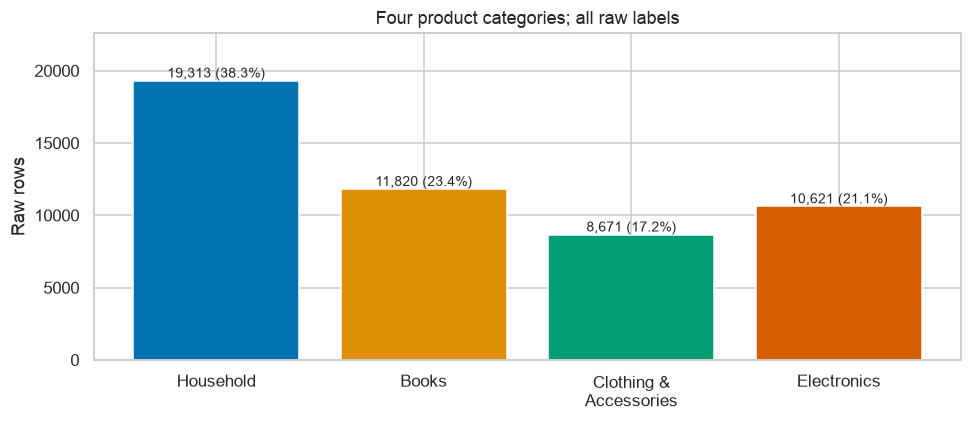

In [4]:
balance = raw.label.value_counts().reindex(LABELS, fill_value=0).rename("raw_N").to_frame()
balance["raw_pct"] = 100 * balance.raw_N / len(raw)
balance["nonempty_N"] = analysis.label.value_counts().reindex(LABELS, fill_value=0)
balance["exact_unique_N"] = exact_unique.label.value_counts().reindex(LABELS, fill_value=0)
balance["exact_unique_pct"] = 100 * balance.exact_unique_N / len(exact_unique)
imbalance_ratio = balance.raw_N.max() / balance.raw_N.min()
unique_imbalance_ratio = balance.exact_unique_N.max() / balance.exact_unique_N.min()
show_table(balance.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([x.replace(" & ", " &\n") for x in LABELS], balance.raw_N, color=list(COLORS.values()))
for bar, share in zip(bars, balance.raw_pct):
    ax.annotate(f"{int(bar.get_height()):,} ({share:.1f}%)",
                (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom", fontsize=9)
ax.set(ylabel="Raw rows", title="Four product categories; all raw labels", ylim=(0, balance.raw_N.max()*1.17))
plt.tight_layout(); plt.show()
display(prose(f"**Observed:** largest/smallest raw class ratio is **{imbalance_ratio:.2f}×** "
                 f"({balance.raw_N.idxmax()} versus {balance.raw_N.idxmin()}); after exact deduplication it is "
                 f"**{unique_imbalance_ratio:.2f}×**. Report macro and per-class outcomes in future "
                 "comparisons; these counts do not establish that resampling will help."))

### Exact duplicates, canonical duplicates and leakage clues

An exact key is the unmodified observed text. The audit-only canonical key applies **Unicode
NFKC → lowercase → collapse Unicode whitespace and strip**. It retains numeric content and
punctuation, although NFKC folds compatibility forms (for example full-width digits). It is
neither lossless nor the final normalization pipeline.

For each key, a duplicate **group** has at least two rows, while **redundant rows** are
$\sum_g(n_g-1)$. Rows belonging to duplicate groups include their first occurrences.
Conflicts mean more than one observed label for the same key. Missing/blank texts and invalid
labels have already been excluded; no missing values are treated as a shared product.

In [5]:
exact_groups = duplicate_groups(analysis, analysis.text)
canonical_keys = analysis.text.map(canonical_key)
canonical_groups = duplicate_groups(analysis, canonical_keys)
duplicate_audit = pd.DataFrame([
    {"key": name, "unique_groups": len(groups), "duplicate_groups": int(groups.rows.gt(1).sum()),
     "rows_in_duplicate_groups": int(groups.loc[groups.rows.gt(1), "rows"].sum()),
     "redundant_rows": int((groups.rows-1).sum()),
     "redundant_pct_main": 100*(groups.rows-1).sum()/len(analysis),
     "conflicting_label_groups": int(groups.labels.gt(1).sum()),
     "rows_in_conflicting_groups": int(groups.loc[groups.labels.gt(1), "rows"].sum())}
    for name, groups in [("exact raw text", exact_groups), ("NFKC/lower/whitespace (audit)", canonical_groups)]
]).set_index("key")
show_table(duplicate_audit.round(3))

# Short escaped real examples; show both labels and original file indices.
examples = []
for key in exact_groups.loc[exact_groups.rows.gt(1)].sort_values("rows", ascending=False).head(3).index:
    rows = analysis.loc[analysis.text.eq(key)]
    examples.append({"kind": "exact duplicate", "row_indices": str(rows.index.tolist()[:8]),
                     "labels": ", ".join(sorted(rows.label.unique())), "group_N": len(rows),
                     "excerpt": key[:180]})
canon_frame = analysis.assign(canonical_key=canonical_keys)
canon_variants = canon_frame.groupby("canonical_key").text.nunique()
for key in canon_variants[canon_variants.gt(1)].head(2).index:
    rows = canon_frame.loc[canon_frame.canonical_key.eq(key)].drop_duplicates("text").head(2)
    for idx, row in rows.iterrows():
        examples.append({"kind": "canonical-only variant", "row_indices": str(idx),
                         "labels": row.label, "group_N": int(canonical_groups.loc[key, "rows"]),
                         "excerpt": repr(row.text[:180])})
show_table(pd.DataFrame(examples), "Real duplicate examples (escaped, abbreviated)", collapse=True, index=False)
conflict_examples = canon_frame.loc[canon_frame.canonical_key.isin(canonical_groups.index[canonical_groups.labels.gt(1)])]
show_table(conflict_examples.assign(text=conflict_examples.text.str.slice(0,180))[["label", "text"]].head(8),
           "Conflicting-label examples (empty means none detected)", collapse=True)
display(prose(f"**Observed:** {duplicate_audit.iloc[0].duplicate_groups:,.0f} exact duplicate groups "
                 f"contain {duplicate_audit.iloc[0].redundant_rows:,.0f} redundant rows "
                 f"(**{duplicate_audit.iloc[0].redundant_pct_main:.2f}%** of the main view). "
                 f"Canonicalization adds **{int(duplicate_audit.iloc[1].redundant_rows-duplicate_audit.iloc[0].redundant_rows):,}** "
                 f"redundant rows; conflicting canonical-label groups = **{int(duplicate_audit.iloc[1].conflicting_label_groups)}**. "
                 "Absence of exact-key label conflicts does not establish annotation correctness."))

,unique_groups,duplicate_groups,rows_in_duplicate_groups,redundant_rows,redundant_pct_main,conflicting_label_groups,rows_in_conflicting_groups
key,,,,,,,
exact raw text,27802,13979,36601,22622,44.864,0,0
NFKC/lower/whitespace (audit),27752,13987,36659,22672,44.963,0,0


kind,row_indices,labels,group_N,excerpt
exact duplicate,"[19466, 19766, 20158, 20834, 21186, 24479, 24481, 24499]",Books,30,"Think & Grow Rich About the Author NAPOLEON HILL, born in Pound, Southwest Virginia in 1883, was a very successful American author in the area of the new thought movement—one of th"
exact duplicate,"[22339, 22349, 22354, 22366, 22459, 22474, 22479, 22914]",Books,29,"The Power of Your Subconscious Mind: Unlock Your Master Key to Success About the Author Joseph Murphy was a Divine Science minister and author. Murphy was born in Ireland, the son"
exact duplicate,"[40519, 40520, 41091, 41108, 41975, 42002, 42021, 42023]",Electronics,26,HP 680 Original Ink Advantage Cartridge (Black) Colour:Black Make the most of every memory when you use Original HP Ink cartridges for your photos as every print is developed wit
canonical-only variant,20707,Books,2,'365 Tales of Indian Mythology'
canonical-only variant,20735,Books,2,'365 Tales of Indian Mythology '
canonical-only variant,1782,Household,4,"""@home by Nilkamal Fern 6 Seater Dining Table Set (Erin Brown) @home presents a wide showcase of modern furniture that's designed to seamlessly blend with your interiors. Crafted f"""
canonical-only variant,1793,Household,4,"""@home by Nilkamal Fern 6 Seater Dining Table Set (Erin Brown) @home presents a wide showcase of modern furniture that's designed to seamlessly blend with your interiors. Crafted fo"""


,label,text


A bounded near-duplicate **illustration**, not a prevalence estimate: sort distinct canonical
texts lexicographically, inspect at most the first 500 adjacent pairs sharing the first
60 characters, and compute whitespace-token-set Jaccard similarity. Report examples with
Jaccard ≥0.90. Shared prefixes bias this search toward similar listings; bag-of-words overlap
ignores word order. This is only evidence that exact deduplication can leave related products,
not a complete deduplication algorithm or an all-pairs $N\times N$ matrix.

In [6]:
ordered = sorted(canonical_groups.index)
candidate_pairs = islice(((a,b) for a,b in zip(ordered, ordered[1:]) if a[:60] == b[:60]), 500)
near_rows = []
near_candidate_n = 0
for a,b in candidate_pairs:
    near_candidate_n += 1
    sa, sb = set(a.split()), set(b.split())
    similarity = len(sa & sb) / len(sa | sb)
    if similarity >= 0.90:
        ia = int(canon_frame.index[canon_frame.canonical_key.eq(a)][0])
        ib = int(canon_frame.index[canon_frame.canonical_key.eq(b)][0])
        # Include the region of the first difference, not only a shared product title.
        difference = next((i for i,(x,y) in enumerate(zip(a,b)) if x != y), min(len(a),len(b)))
        start = max(0,difference-45)
        near_rows.append({"row_A": ia, "row_B": ib, "Jaccard": similarity,
                          "label_A": analysis.loc[ia,"label"], "label_B": analysis.loc[ib,"label"],
                          "title_A": analysis.loc[ia,"text"][:90],
                          "raw_window_A": analysis.loc[ia,"text"][max(0,start):start+170],
                          "raw_window_B": analysis.loc[ib,"text"][max(0,start):start+170]})
near_examples = pd.DataFrame(near_rows)
show_table(near_examples.head(3).round(4), "Bounded near-duplicate examples", index=False)
print(f"Inspected {near_candidate_n} candidate pairs; {len(near_examples)} met this illustrative threshold. Not a corpus rate.")
display(prose("**Implication:** random row splitting can place identical descriptions or related "
                 "product variants on both sides. Later define exact/canonical groups before splitting, "
                 "review variant families and audit cross-partition near matches. Fit learned vocabulary "
                 "only on training folds. Exact deduplication alone does not ensure independence."))

row_A,row_B,Jaccard,label_A,label_B,title_A,raw_window_A,raw_window_B
11501,11505,0.9394,Household,Household,1pcs Wood Fish Shaped Rice Spoon Non Stick Rice Paddle Wooden Spoon Cute Fish Rice Spoon S,Scoop Potato Meal Server Cooking Tools Color Brown Material:Wood; Brand Name:None; Length:About 21cm; Flatware Type:Spoons; Feature 1:Kids Spoon; Feature 2:Feature:Eco-Fr,Scoop Potato Meal Server Cooking Tools Color White Material:Wood; Brand Name:None; Length:About 21cm; Flatware Type:Spoons; Feature 1:Kids Spoon; Feature 2:Feature:Eco-Fr
21742,21764,0.9828,Books,Books,40 Years' Chapterwise Topicwise Solved Papers (2018-1979) IIT JEE Mathematics About the Au,"Topicwise Solved Papers (2018-1979) IIT JEE Mathematics About the Author An editorial team of highly skilled professionals at Arihant, works hand in glove to ensure that","Topicwise Solved Papers (2018-1979) IIT JEE Physics About the Author An editorial team of highly skilled professionals at Arihant, works hand in glove to ensure that the"
19441,23146,0.9939,Books,Books,A Dance with Dragons (HBO Tie-in Edition): A Song of Ice and Fire: Book Five: A Novel Revi,"ies in the history of fantasy.”—Los Angeles Times About the Author George R. R. Martin is the #1 New York Times bestselling author of many novels, including the acclaime",ies in the history of fantasy.”—Los Angeles TimesFrom the Hardcover edition. About the Author George R. R. Martin is the #1 New York Times bestselling author of many nov


Inspected 500 candidate pairs; 210 met this illustrative threshold. Not a corpus rate.


### Surface-pattern quality audit

These transparent detectors flag **presence per document**, so one text may match several rows.
HTML tags use a broad tag-shaped regex; entities use named or numeric reference syntax, not an
HTML parser. URL includes `http(s)`/`www`; mention/hashtag use `@`/`#` followed by word
characters. ASCII uppercase and digit patterns are shown explicitly. Unusual whitespace means
leading/trailing whitespace, repeated whitespace, tab/newline/carriage return or a nonbreaking space.

Matches are candidates for inspection. A hashtag may be a product code, a mention may be an
address fragment, and angle brackets may express specifications. None automatically implies
noise or warrants removal. All excerpts below are escaped and truncated.

In [7]:
PATTERNS = {
    "HTML tag-shaped": r"</?[A-Za-z][^>]*>",
    "HTML entity-shaped": r"&(?:[A-Za-z][A-Za-z0-9]+|#[0-9]+|#x[0-9A-Fa-f]+);",
    "URL": r"(?i)\b(?:https?://|www\.)\S+",
    "mention-shaped": r"(?<!\w)@\w+",
    "hashtag-shaped": r"(?<!\w)#\w+",
    "ASCII uppercase": r"[A-Z]",
    "digit": r"\d",
    "unusual whitespace": r"^\s|\s$|\s{2,}|[\t\n\r\u00a0]",
}
pattern_flags = pd.DataFrame({name: analysis.text.str.contains(pattern, regex=True, na=False)
                              for name,pattern in PATTERNS.items()}, index=analysis.index)
pattern_audit = pd.DataFrame({"pattern": list(PATTERNS), "regex": list(PATTERNS.values()),
                              "documents": pattern_flags.sum().values,
                              "pct_main": 100*pattern_flags.mean().values})
show_table(pattern_audit.round(3), index=False)
pattern_examples = []
for name,pattern in PATTERNS.items():
    for idx in pattern_flags.index[pattern_flags[name]][:2]:
        text = analysis.loc[idx,"text"]
        match = re.search(pattern,text)
        start = max(0,match.start()-55)
        pattern_examples.append({"detector":name, "row":idx, "label":analysis.loc[idx,"label"],
                                 "match":repr(match.group()[:65]), "context":repr(text[start:start+190])})
show_table(pd.DataFrame(pattern_examples), "Real surface-pattern examples — escaped", collapse=True, index=False)
pattern_counts = pattern_audit.set_index("pattern").documents
special_names = ["HTML tag-shaped", "HTML entity-shaped", "URL", "mention-shaped", "hashtag-shaped"]
display(prose("**Observed:** " + "; ".join(f"{name}: **{int(pattern_counts[name]):,}** texts" for name in special_names)
                 + f". Digits occur in **{pattern_flags['digit'].mean():.1%}** of descriptions. "
                 "Inspect codes, quantities and units before any numeric-removal rule; a match is not a cleaning decision."))

pattern,regex,documents,pct_main
HTML tag-shaped,</?[A-Za-z][^>]*>,36,0.071
HTML entity-shaped,&(?:[A-Za-z][A-Za-z0-9]+|#[0-9]+|#x[0-9A-Fa-f]+);,53,0.105
URL,(?i)\b(?:https?://|www\.)\S+,328,0.65
mention-shaped,(?<!\w)@\w+,152,0.301
hashtag-shaped,(?<!\w)#\w+,335,0.664
ASCII uppercase,[A-Z],50421,99.994
digit,\d,39427,78.191
unusual whitespace,"^\s|\s$|\s{2,}|[\t\n\r\u00a0]",16727,33.173


detector,row,label,match,context
HTML tag-shaped,3790,Household,'</span>',"""marks and doesn't affect the appearance of the cabinets</span></li> Suitable for babies 6 months-5 years old Can be used on the refrigerator, cabinets, windows, and other double open bookcas"""
HTML tag-shaped,3796,Household,'</span>',"""marks and doesn't affect the appearance of the cabinets</span></li> Suitable for babies 6 months-5 years old Can be used on the refrigerator, cabinets, windows, and other double open bookcas"""
HTML entity-shaped,456,Household,'&Amp;',"""nvenient To Use Description:1. Material:Stainless Steel&Amp;Plastic2. Color:As Pictures3. Length Of Knitting Needles:14Cm/5.51''(Approx)4. Size Of Soft Silicone Handle Aluminum Hooks Crochet"""
HTML entity-shaped,3693,Household,'&Apos;',"' A Delicate Sense Of Ambiance To Any Space. Whether You&Apos;Re Decorating For A Special Occasion, Festival Or A Wedding These Tealights Can Be Scatter Around For A Soft Candlelit Glow.'"
URL,716,Household,'https://www.youtube.com/watch?v=OEnIE6ICVLU',"'e too. You can see its folding instruction on Youtube ""https://www.youtube.com/watch?v=OEnIE6ICVLU ""'"
URL,1319,Household,'https://postimg.org/image/5o0qh90hx/',"' check this link to see how to fold the bedrail down : https://postimg.org/image/5o0qh90hx/ Assembly note: Please note that to fix this product properly, there are two arms that go below the'"
mention-shaped,671,Household,'@home',"'@home by Nilkamal Edward 3 Door Wardrobe (Melamine Finish, Walnut) Who doesn’t need a wardrobe that is both storage-efficient and stylish? Nilkamal’s Edward wardrobe belongs to that category'"
mention-shaped,690,Household,'@home',"'@home by Nilkamal Edward 4 Door Wardrobe (Walnut) Enhance the look of your bedroom with this wardrobe. Designed skilfully from quality materials to combine functionality with aesthetics, thi'"
hashtag-shaped,123,Household,'#412585',"'762, 4772 and Hobbylock 2.0 - Part Number: Upper Knife #412585+ Lower Knife #550449 - Upper Knife Size: Approx. 25 x 8mm/0.98 x 0.31 inch, - Lower Knife Size: Approx. 40 x 8mm/1.57 x 0.31 in'"
hashtag-shaped,142,Household,'#60',"""White Nylon #60 Beading Cord - 300 Feet Cord Basics Nylon Beading Cord 60lb 300'-White"""


### Raw length distributions

**Character count** is Python Unicode code-point length of the original string, including
spaces/punctuation (not encoded byte length or grapheme clusters). **Word count** is
`len(text.split())`: runs separated by Unicode whitespace, with punctuation/numbers retained
inside runs. Neither strips HTML nor performs linguistic tokenization. Missing/blank texts
have no assigned length and are excluded from the main view, rather than imputed to zero.
Standard deviation is sample SD (`ddof=1`); percentiles use pandas' default linear interpolation.

Show one summary table per metric. Histograms display every eligible document on a
`log1p` length scale, preserving the right tail; ECDFs on the same scale show class ordering
without bin dependence. The log transformation is for display, not a change to raw lengths.
No observations are trimmed or hidden outside a chosen x limit.

,N,mean,std,median,Q1,Q3,P95,max
label,,,,,,,,
Household,19313,108.64,97.98,83.0,44.0,146.0,284.0,1791
Books,11820,135.61,265.43,78.0,13.0,169.0,440.1,8181
Clothing & Accessories,8670,72.37,63.72,56.0,29.0,92.0,213.0,581
Electronics,10621,134.54,129.03,99.0,43.0,194.0,329.0,1997


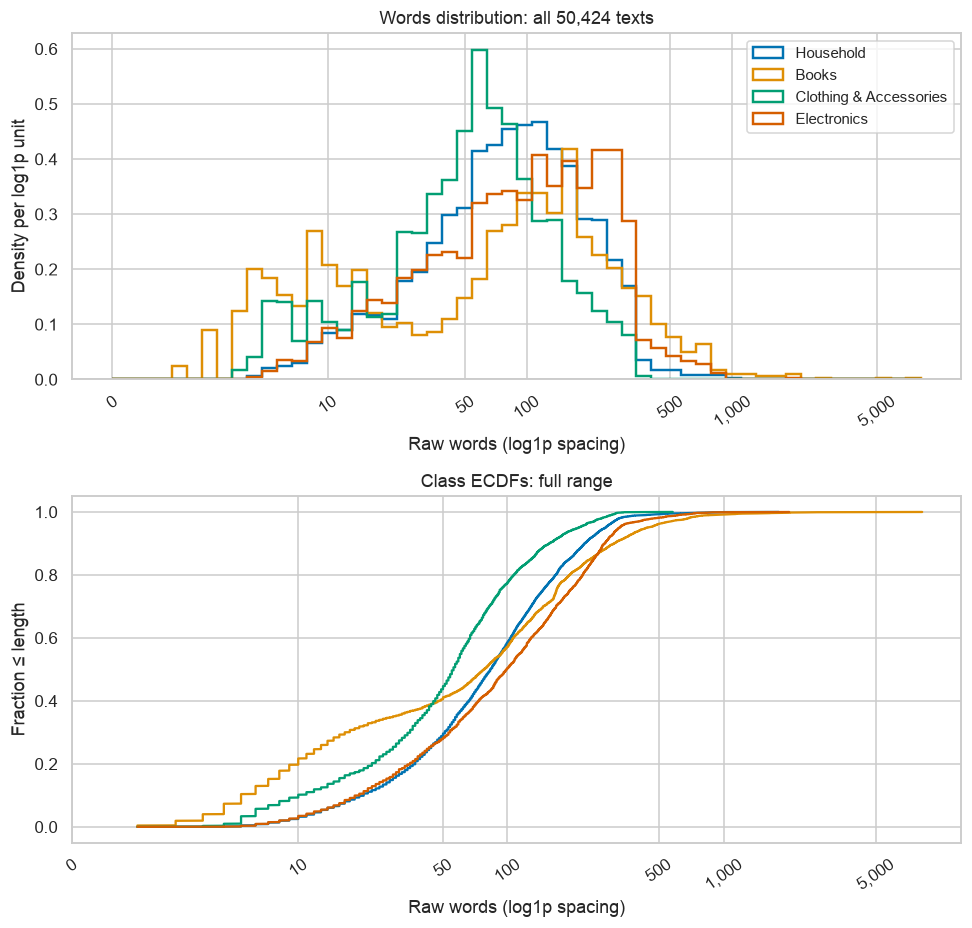

,N,mean,std,median,Q1,Q3,P95,max
label,,,,,,,,
Household,19313,671.54,606.38,515.0,274.0,903.0,1737.0,10168
Books,11820,857.01,1624.80,495.0,81.0,1064.0,2836.3,50403
Clothing & Accessories,8670,446.30,393.46,342.0,181.0,568.0,1286.1,3474
Electronics,10621,851.11,813.68,630.0,293.0,1222.0,2018.0,12473


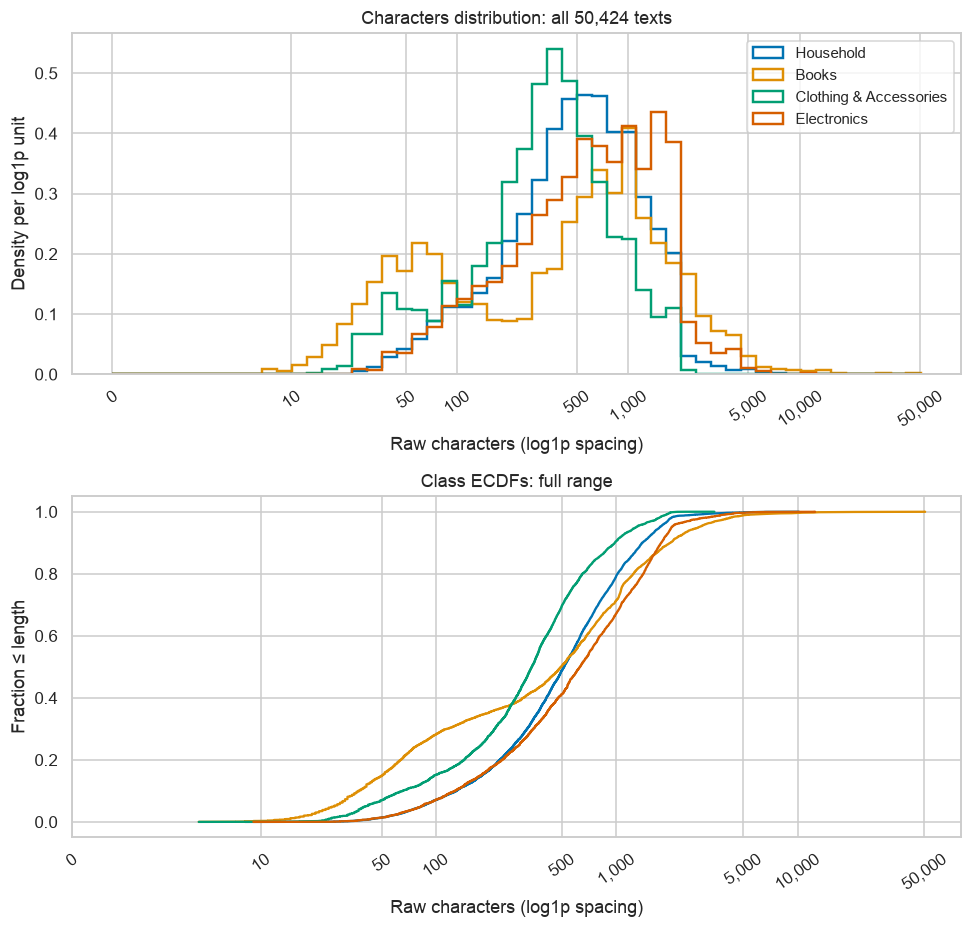

,measured
word_P95,311.000
word_P99,611.000
word_max,8181.000
character_P95,1940.000
character_P99,3847.000
character_max,50403.000
texts_above_256_whitespace_words,4715.000
pct_above_256_whitespace_words,9.351
texts_above_512_whitespace_words,759.000
pct_above_512_whitespace_words,1.505


In [8]:
analysis["characters"] = analysis.text.str.len().astype("int64")
analysis["words"] = analysis.text.map(lambda t: len(t.split())).astype("int64")
exact_unique = analysis.loc[exact_unique.index].copy()

def length_summary(frame, metric):
    return frame.groupby("label")[metric].agg(
        N="size", mean="mean", std="std", median="median",
        Q1=lambda s:s.quantile(.25), Q3=lambda s:s.quantile(.75),
        P95=lambda s:s.quantile(.95), max="max").reindex(LABELS)
length_tables = {metric:length_summary(analysis,metric) for metric in ["words","characters"]}
for metric,summary in length_tables.items():
    show_table(summary.round(2), f"Raw {metric} by class — main nonempty view")
    fig,axes = plt.subplots(2,1,figsize=(9,8.6))
    maximum = analysis[metric].max()
    bins = np.linspace(0,np.log1p(maximum),55)
    for label in LABELS:
        values = analysis.loc[analysis.label.eq(label),metric].to_numpy()
        axes[0].hist(np.log1p(values),bins=bins,density=True,histtype="step",linewidth=1.6,
                     color=COLORS[label],label=label)
        values = np.sort(values)
        axes[1].plot(np.log1p(values),np.arange(1,len(values)+1)/len(values),color=COLORS[label],label=label)
    ticks = np.array([0,10,50,100,500,1000,5000,10000,50000])
    ticks = ticks[ticks <= maximum]
    for ax in axes:
        ax.set_xticks(np.log1p(ticks),labels=[f"{v:,}" for v in ticks],rotation=35)
        ax.set_xlabel(f"Raw {metric} (log1p spacing)")
    axes[0].set(title=f"{metric.capitalize()} distribution: all {len(analysis):,} texts",ylabel="Density per log1p unit")
    axes[1].set(title="Class ECDFs: full range",ylabel="Fraction ≤ length")
    axes[0].legend(fontsize=10)
    plt.tight_layout();plt.show()
long_tail = pd.Series({
    "word_P95":analysis.words.quantile(.95), "word_P99":analysis.words.quantile(.99),
    "word_max":analysis.words.max(), "character_P95":analysis.characters.quantile(.95),
    "character_P99":analysis.characters.quantile(.99), "character_max":analysis.characters.max(),
    "texts_above_256_whitespace_words":int(analysis.words.gt(256).sum()),
    "pct_above_256_whitespace_words":100*analysis.words.gt(256).mean(),
    "texts_above_512_whitespace_words":int(analysis.words.gt(512).sum()),
    "pct_above_512_whitespace_words":100*analysis.words.gt(512).mean(),
    "observations_outside_plot_range":0,
},name="measured")
show_table(long_tail.to_frame().round(3))
medians=length_tables["words"]["median"]
display(prose(f"**Observed:** class median whitespace-word lengths range from **{medians.min():.0f}** "
                 f"({medians.idxmin()}) to **{medians.max():.0f}** ({medians.idxmax()}); "
                 f"the corpus P95 is **{long_tail.word_P95:.0f}**, versus maximum **{long_tail.word_max:,.0f}**. "
                 "The long tail motivates later sequence-limit/chunking checks. The 256/512-word counts "
                 "are rough exposure diagnostics, not model-token truncation rates. Sentence Transformer "
                 "limits and subword lengths depend on the chosen model/tokenizer, which is not loaded here."))

### Six pairwise Mann–Whitney comparisons per metric

The U statistic below refers to class A. Holm-adjusted p-values share one family across
**six pairs × two length metrics = 12** tests for the main view. A second independent
adjustment family covers the corresponding 12 sensitivity tests. These families are declared
in advance; no per-pair selection occurs. Exact duplicate removal changes row weights and
sample sizes, so compare practical effects and medians as well as significance decisions.

`0 (underflow)` means numerical underflow of a computed p-value, never a zero-probability
claim. Full U/raw p/Holm p/effect-size values are retained in Python tables and saved outputs.

In [9]:
def pairwise_lengths(frame, view):
    records=[]
    for metric in ["words","characters"]:
        for left,right in combinations(LABELS,2):
            a=frame.loc[frame.label.eq(left),metric].to_numpy()
            b=frame.loc[frame.label.eq(right),metric].to_numpy()
            result=stats.mannwhitneyu(a,b,alternative="two-sided",method="asymptotic",use_continuity=True)
            records.append({"view":view,"metric":metric,"A":left,"B":right,
                            "n_A":len(a),"n_B":len(b),"median_A":np.median(a),"median_B":np.median(b),
                            "median_A_minus_B":np.median(a)-np.median(b),
                            "U_A":result.statistic,"p_raw":result.pvalue,
                            "rank_biserial":2*result.statistic/(len(a)*len(b))-1})
    table=pd.DataFrame(records)
    table["p_Holm"]=multipletests(table.p_raw.to_numpy(),alpha=ALPHA,method="holm")[1]
    table["reject_Holm"]=table.p_Holm.lt(ALPHA)
    return table

mw_main=pairwise_lengths(analysis,"nonempty main")
mw_unique=pairwise_lengths(exact_unique,"exact-unique sensitivity")
pformat=lambda p:"0 (underflow)" if p==0 else f"{p:.2e}"
# Keep inferential results visible within the book's reading column.
# Full sample sizes, medians and unrounded values remain in the supporting tables.
ALIASES={"Household":"HH","Books":"BK","Clothing & Accessories":"CA","Electronics":"EL"}
display(prose("**Pair key:** HH = Household; BK = Books; CA = Clothing & Accessories; "
                 "EL = Electronics. Δmedian and signed effect refer to A minus B. "
                 "Each main table below contains all six class pairs; supporting tables retain all columns."))
for metric in ["words","characters"]:
    compact=mw_main.loc[mw_main.metric.eq(metric)].copy()
    compact["A vs B"]=[f"{ALIASES[a]} / {ALIASES[b]}" for a,b in zip(compact.A,compact.B)]
    compact=compact.rename(columns={"median_A_minus_B":"Δmedian","U_A":"U(A)",
                                    "rank_biserial":"r_rb","p_raw":"p raw","p_Holm":"p Holm"})
    show_table(compact[["A vs B","Δmedian","U(A)","p raw","p Holm","r_rb"]],
               f"Main {metric}: six two-sided comparisons (Holm family includes both metrics)",index=False,
               formatters={"p raw":pformat,"p Holm":pformat,"U(A)":lambda x:f"{x:,.1f}",
                           "Δmedian":lambda x:f"{x:+.1f}","r_rb":lambda x:f"{x:+.4f}"})
for title,table in [("Full main view: 12-test Holm family",mw_main),
                    ("Full exact-unique sensitivity: separate 12-test Holm family",mw_unique)]:
    show_table(table.drop(columns="view"),title,collapse=True,index=False,
               formatters={"p_raw":pformat,"p_Holm":pformat,"U_A":lambda x:f"{x:,.1f}",
                           "rank_biserial":lambda x:f"{x:+.4f}"})

sensitivity = mw_main[["metric","A","B","median_A_minus_B","rank_biserial","reject_Holm"]].merge(
    mw_unique[["metric","A","B","median_A_minus_B","rank_biserial","reject_Holm"]],
    on=["metric","A","B"],suffixes=("_main","_unique"))
sensitivity["effect_change"]=sensitivity.rank_biserial_unique-sensitivity.rank_biserial_main
for metric in ["words","characters"]:
    small=sensitivity.loc[sensitivity.metric.eq(metric)].copy()
    small["A vs B"]=[f"{ALIASES[a]} / {ALIASES[b]}" for a,b in zip(small.A,small.B)]
    small=small.rename(columns={"rank_biserial_main":"r main","rank_biserial_unique":"r unique",
                                "effect_change":"Δr","median_A_minus_B_unique":"Δmedian unique"})
    show_table(small[["A vs B","r main","r unique","Δr","Δmedian unique"]].round(4),
               f"{metric.capitalize()} sensitivity: effect magnitude after exact deduplication",index=False)
show_table(sensitivity.round(4),"Practical-effect sensitivity",collapse=True,index=False)
unique_length_tables={metric:length_summary(exact_unique,metric) for metric in ["words","characters"]}
for metric,table in unique_length_tables.items():
    show_table(table.round(2),f"Exact-unique {metric} summary",collapse=True)
strongest=mw_main.loc[mw_main.rank_biserial.abs().idxmax()]
weakest=mw_main.loc[mw_main.rank_biserial.abs().idxmin()]
display(prose(f"**Observed:** Holm rejects **{int(mw_main.reject_Holm.sum())}/12** main-view "
                 f"and **{int(mw_unique.reject_Holm.sum())}/12** exact-unique comparisons. "
                 f"The largest |rank-biserial| is **{abs(strongest.rank_biserial):.3f}** "
                 f"({strongest.metric}: {strongest.A} vs {strongest.B}); the smallest is "
                 f"**{abs(weakest.rank_biserial):.3f}** ({weakest.metric}: {weakest.A} vs {weakest.B}). "
                 f"The largest absolute effect change after exact deduplication is "
                 f"**{sensitivity.effect_change.abs().max():.3f}**. "
                 "Statistical detectability at these sample sizes is not equivalent to a large practical "
                 "difference. Exact deduplication does not remove all product-family dependence or make p-values fully calibrated."))

A vs B,Δmedian,U(A),p raw,p Holm,r_rb
HH / BK,+5.0,"124,366,477.5",2.69e-40,8.08e-40,+0.0896
HH / CA,+27.0,"105,430,953.0",1.85e-264,1.67e-263,+0.2593
HH / EL,-16.0,"92,515,957.0",8.43e-45,3.37e-44,-0.0979
BK / CA,+22.0,"56,338,331.5",3.56e-34,7.12e-34,+0.0995
BK / EL,-21.0,"52,207,442.5",2.33e-105,1.87e-104,-0.1683
CA / EL,-43.0,"31,062,737.0",0 (underflow),0 (underflow),-0.3253


A vs B,Δmedian,U(A),p raw,p Holm,r_rb
HH / BK,+20.0,"122,759,379.5",4.07e-29,4.07e-29,+0.0755
HH / CA,+173.0,"105,993,636.0",3.19e-278,3.19e-277,+0.2660
HH / EL,-115.0,"90,545,301.5",2.51e-63,1.50e-62,-0.1172
BK / CA,+153.0,"57,157,250.0",1.98e-45,9.89e-45,+0.1155
BK / EL,-135.0,"52,270,163.5",3.95e-104,2.77e-103,-0.1673
CA / EL,-288.0,"29,974,521.0",0 (underflow),0 (underflow),-0.3490


metric,A,B,n_A,n_B,median_A,median_B,median_A_minus_B,U_A,p_raw,rank_biserial,p_Holm,reject_Holm
words,Household,Books,19313,11820,83.0,78.0,5.0,"124,366,477.5",2.69e-40,+0.0896,8.08e-40,True
words,Household,Clothing & Accessories,19313,8670,83.0,56.0,27.0,"105,430,953.0",1.85e-264,+0.2593,1.67e-263,True
words,Household,Electronics,19313,10621,83.0,99.0,-16.0,"92,515,957.0",8.43e-45,-0.0979,3.37e-44,True
words,Books,Clothing & Accessories,11820,8670,78.0,56.0,22.0,"56,338,331.5",3.56e-34,+0.0995,7.12e-34,True
words,Books,Electronics,11820,10621,78.0,99.0,-21.0,"52,207,442.5",2.33e-105,-0.1683,1.87e-104,True
words,Clothing & Accessories,Electronics,8670,10621,56.0,99.0,-43.0,"31,062,737.0",0 (underflow),-0.3253,0 (underflow),True
characters,Household,Books,19313,11820,515.0,495.0,20.0,"122,759,379.5",4.07e-29,+0.0755,4.07e-29,True
characters,Household,Clothing & Accessories,19313,8670,515.0,342.0,173.0,"105,993,636.0",3.19e-278,+0.2660,3.19e-277,True
characters,Household,Electronics,19313,10621,515.0,630.0,-115.0,"90,545,301.5",2.51e-63,-0.1172,1.50e-62,True
characters,Books,Clothing & Accessories,11820,8670,495.0,342.0,153.0,"57,157,250.0",1.98e-45,+0.1155,9.89e-45,True


metric,A,B,n_A,n_B,median_A,median_B,median_A_minus_B,U_A,p_raw,rank_biserial,p_Holm,reject_Holm
words,Household,Books,10564,6256,84.0,73.0,11.0,"36,441,975.0",6.14e-29,+0.1028,3.69e-28,True
words,Household,Clothing & Accessories,10564,5674,84.0,56.0,28.0,"37,588,743.5",1.20e-157,+0.2542,1.08e-156,True
words,Household,Electronics,10564,5308,84.0,97.0,-13.0,"25,618,624.5",6.72e-19,-0.0863,2.02e-18,True
words,Books,Clothing & Accessories,6256,5674,73.0,56.0,17.0,"19,013,134.0",1.66e-11,+0.0713,1.66e-11,True
words,Books,Electronics,6256,5308,73.0,97.0,-24.0,"13,777,941.0",3.39e-56,-0.1702,2.71e-55,True
words,Clothing & Accessories,Electronics,5674,5308,56.0,97.0,-41.0,"10,453,565.0",2.41e-169,-0.3058,2.66e-168,True
characters,Household,Books,10564,6256,518.0,472.0,46.0,"35,934,768.5",2.16e-21,+0.0875,8.64e-21,True
characters,Household,Clothing & Accessories,10564,5674,518.0,344.5,173.5,"37,819,707.5",3.23e-167,+0.2619,3.23e-166,True
characters,Household,Electronics,10564,5308,518.0,616.5,-98.5,"25,134,892.5",1.64e-26,-0.1035,8.22e-26,True
characters,Books,Clothing & Accessories,6256,5674,472.0,344.5,127.5,"19,324,047.0",4.95e-17,+0.0888,9.90e-17,True


A vs B,r main,r unique,Δr,Δmedian unique
HH / BK,0.0896,0.1028,0.0132,11.0
HH / CA,0.2593,0.2542,-0.0051,28.0
HH / EL,-0.0979,-0.0863,0.0117,-13.0
BK / CA,0.0995,0.0713,-0.0282,17.0
BK / EL,-0.1683,-0.1702,-0.0019,-24.0
CA / EL,-0.3253,-0.3058,0.0195,-41.0


A vs B,r main,r unique,Δr,Δmedian unique
HH / BK,0.0755,0.0875,0.0120,46.0
HH / CA,0.2660,0.2619,-0.0041,173.5
HH / EL,-0.1172,-0.1035,0.0137,-98.5
BK / CA,0.1155,0.0888,-0.0267,127.5
BK / EL,-0.1673,-0.1660,0.0013,-144.5
CA / EL,-0.3490,-0.3282,0.0208,-272.0


metric,A,B,median_A_minus_B_main,rank_biserial_main,reject_Holm_main,median_A_minus_B_unique,rank_biserial_unique,reject_Holm_unique,effect_change
words,Household,Books,5.0,0.0896,True,11.0,0.1028,True,0.0132
words,Household,Clothing & Accessories,27.0,0.2593,True,28.0,0.2542,True,-0.0051
words,Household,Electronics,-16.0,-0.0979,True,-13.0,-0.0863,True,0.0117
words,Books,Clothing & Accessories,22.0,0.0995,True,17.0,0.0713,True,-0.0282
words,Books,Electronics,-21.0,-0.1683,True,-24.0,-0.1702,True,-0.0019
words,Clothing & Accessories,Electronics,-43.0,-0.3253,True,-41.0,-0.3058,True,0.0195
characters,Household,Books,20.0,0.0755,True,46.0,0.0875,True,0.0120
characters,Household,Clothing & Accessories,173.0,0.2660,True,173.5,0.2619,True,-0.0041
characters,Household,Electronics,-115.0,-0.1172,True,-98.5,-0.1035,True,0.0137
characters,Books,Clothing & Accessories,153.0,0.1155,True,127.5,0.0888,True,-0.0267


,N,mean,std,median,Q1,Q3,P95,max
label,,,,,,,,
Household,10564,107.01,94.01,84.0,44.00,143.0,275.85,1791
Books,6256,139.98,297.69,73.0,12.00,169.0,462.50,8181
Clothing & Accessories,5674,72.63,62.84,56.0,31.00,91.0,209.35,581
Electronics,5308,130.46,123.79,97.0,41.75,191.0,318.00,1997


,N,mean,std,median,Q1,Q3,P95,max
label,,,,,,,,
Household,10564,661.73,580.74,518.0,277.0,893.00,1705.00,10168
Books,6256,888.09,1821.73,472.0,79.0,1070.25,2939.50,50403
Clothing & Accessories,5674,446.90,384.92,344.5,191.0,559.00,1272.35,3474
Electronics,5308,825.01,782.66,616.5,275.0,1199.25,1962.00,12473


### Lexical frequency view, four word clouds and complete top-50 tables

Define a lexical token with Python regex **`[^\W_]+(?:['’][^\W_]+)*`** under Unicode semantics,
after `lower()`: a sequence of Unicode alphanumeric characters, optionally joined by an
internal straight/curly apostrophe. Underscores, hyphens and other punctuation separate tokens;
standalone numbers remain tokens. No Unicode normalization, HTML parsing, stopword removal,
stemming or lemmatization is used here. Lowercasing is a **descriptive lexical view**, not a
write to raw text or a finalized preprocessing pipeline.

Unlike whitespace-word lengths, `USB-C, 3.0` yields lexical `usb`, `c`, `3`, `0`.
Token counts therefore need not equal whitespace-word counts. Punctuation boundaries and
case folding affect types; “vocabulary” always refers to this defined view.

For each class, rank by descending count and alphabetical token order for ties. Table share
is **count / all lexical token occurrences in that class**. Clouds use the same full frequency
dictionary, displaying its top 150 entries; `stopwords=set()`, `collocations=False`,
`normalize_plurals=False`, `repeat=False`. `generate_from_frequencies` bypasses WordCloud's
text parser entirely. Common words remain visible, as required for pre-cleaning EDA.

In [10]:
LEXICAL_RE = re.compile(r"[^\W_]+(?:['’][^\W_]+)*",flags=re.UNICODE)
def lexical_tokens(text):
    return LEXICAL_RE.findall(text.lower())

frequencies={}
for label in LABELS:
    counts=Counter()
    for text in analysis.loc[analysis.label.eq(label),"text"]:
        counts.update(lexical_tokens(text))
    frequencies[label]=dict(sorted(counts.items(),key=lambda item:(-item[1],item[0])))
corpus_counter=Counter()
for counts in frequencies.values():
    corpus_counter.update(counts)
corpus_frequency=dict(sorted(corpus_counter.items(),key=lambda item:(-item[1],item[0])))
top50_tables={}
for label in LABELS:
    counts=frequencies[label]
    total=sum(counts.values())
    top=pd.DataFrame(list(counts.items())[:50],columns=["token","count"])
    top.insert(0,"rank",np.arange(1,len(top)+1))
    top["pct_class_tokens"]=100*top["count"]/total
    top50_tables[label]=top
print("Lexical example:",lexical_tokens("USB-C, 3.0"))
print("Whitespaced words in example:",len("USB-C, 3.0".split()))

Lexical example: ['usb', 'c', '3', '0']
Whitespaced words in example: 2


#### Household

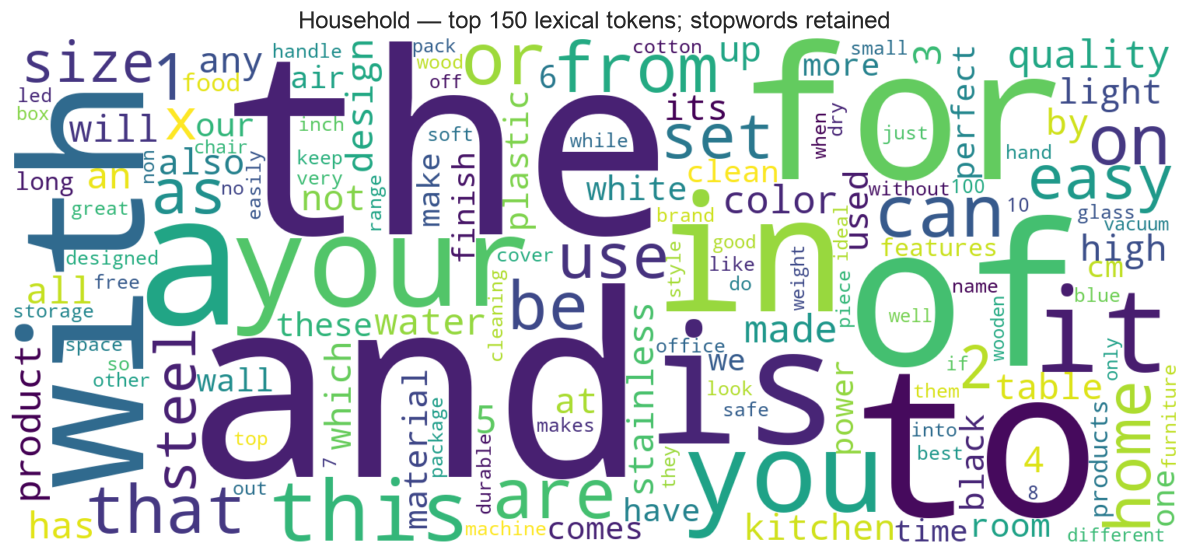

rank,token,count,pct_class_tokens
1,and,67523,3.1537
2,the,67081,3.1331
3,to,43022,2.0094
4,of,38556,1.8008
5,a,34115,1.5934
6,for,33537,1.5664
7,with,28294,1.3215
8,is,26432,1.2345
9,in,25572,1.1944
10,your,21863,1.0211


In [11]:
label='Household'
cloud=WordCloud(width=1500,height=650,background_color="white",max_words=150,
                stopwords=set(),collocations=False,normalize_plurals=False,repeat=False,
                random_state=SEED,colormap="viridis").generate_from_frequencies(frequencies[label])
fig,ax=plt.subplots(figsize=(12,5.2))
ax.imshow(cloud,interpolation="bilinear");ax.axis("off")
ax.set_title(f"{label} — top 150 lexical tokens; stopwords retained",fontsize=16)
plt.tight_layout();plt.show()
show_table(top50_tables[label],f"{label}: complete top-50 (count and share of class tokens)",
           collapse=True,index=False,formatters={"pct_class_tokens":lambda x:f"{x:.4f}"})
top=top50_tables[label]
display(prose(f"**Observed:** the leading token is **{top.iloc[0].token}** "
                 f"({int(top.iloc[0]['count']):,} occurrences); the top 50 account for "
                 f"**{top.pct_class_tokens.sum():.2f}%** of this class's lexical occurrences. "
                 "These raw common-word patterns motivate a later stopword ablation, not automatic removal."))

#### Books

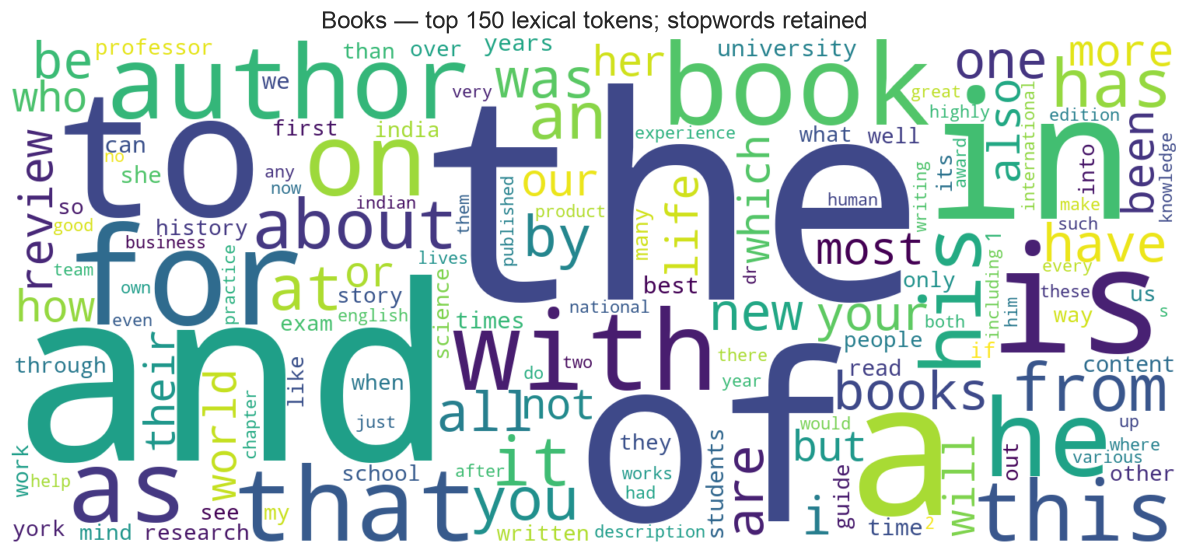

rank,token,count,pct_class_tokens
1,the,90456,5.5366
2,and,64718,3.9612
3,of,58708,3.5934
4,a,35790,2.1906
5,in,31723,1.9417
6,to,31165,1.9075
7,is,21624,1.3235
8,for,17887,1.0948
9,book,11851,0.7254
10,with,11317,0.6927


In [12]:
label='Books'
cloud=WordCloud(width=1500,height=650,background_color="white",max_words=150,
                stopwords=set(),collocations=False,normalize_plurals=False,repeat=False,
                random_state=SEED,colormap="viridis").generate_from_frequencies(frequencies[label])
fig,ax=plt.subplots(figsize=(12,5.2))
ax.imshow(cloud,interpolation="bilinear");ax.axis("off")
ax.set_title(f"{label} — top 150 lexical tokens; stopwords retained",fontsize=16)
plt.tight_layout();plt.show()
show_table(top50_tables[label],f"{label}: complete top-50 (count and share of class tokens)",
           collapse=True,index=False,formatters={"pct_class_tokens":lambda x:f"{x:.4f}"})
top=top50_tables[label]
display(prose(f"**Observed:** the leading token is **{top.iloc[0].token}** "
                 f"({int(top.iloc[0]['count']):,} occurrences); the top 50 account for "
                 f"**{top.pct_class_tokens.sum():.2f}%** of this class's lexical occurrences. "
                 "These raw common-word patterns motivate a later stopword ablation, not automatic removal."))

#### Clothing & Accessories

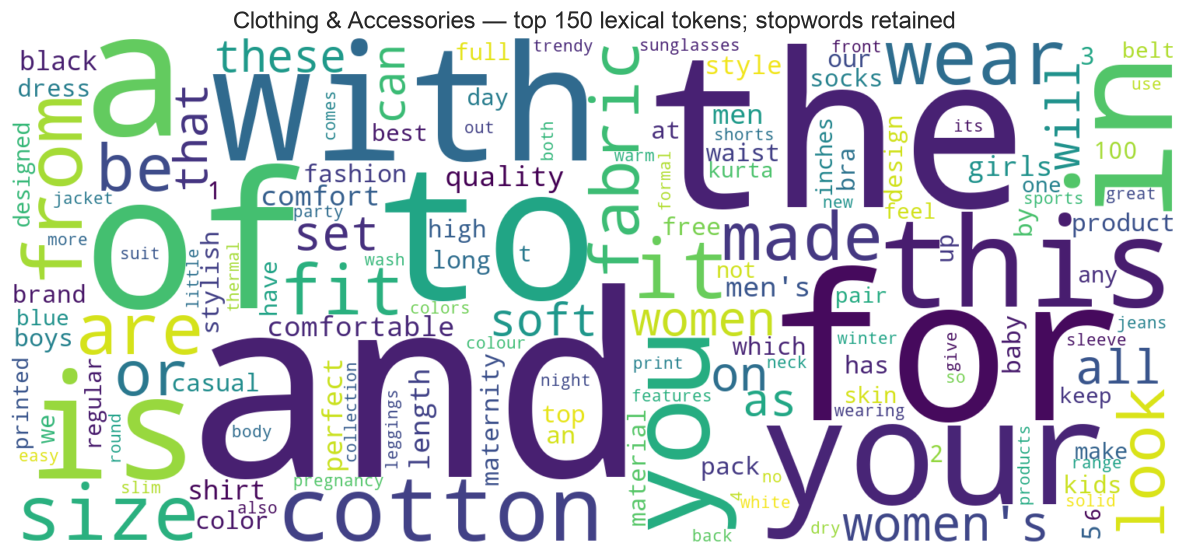

rank,token,count,pct_class_tokens
1,and,21161,3.2791
2,the,14555,2.2554
3,for,12805,1.9843
4,of,11110,1.7216
5,to,10971,1.7001
6,a,9759,1.5123
7,with,9129,1.4146
8,your,7491,1.1608
9,is,7388,1.1448
10,in,7115,1.1025


In [13]:
label='Clothing & Accessories'
cloud=WordCloud(width=1500,height=650,background_color="white",max_words=150,
                stopwords=set(),collocations=False,normalize_plurals=False,repeat=False,
                random_state=SEED,colormap="viridis").generate_from_frequencies(frequencies[label])
fig,ax=plt.subplots(figsize=(12,5.2))
ax.imshow(cloud,interpolation="bilinear");ax.axis("off")
ax.set_title(f"{label} — top 150 lexical tokens; stopwords retained",fontsize=16)
plt.tight_layout();plt.show()
show_table(top50_tables[label],f"{label}: complete top-50 (count and share of class tokens)",
           collapse=True,index=False,formatters={"pct_class_tokens":lambda x:f"{x:.4f}"})
top=top50_tables[label]
display(prose(f"**Observed:** the leading token is **{top.iloc[0].token}** "
                 f"({int(top.iloc[0]['count']):,} occurrences); the top 50 account for "
                 f"**{top.pct_class_tokens.sum():.2f}%** of this class's lexical occurrences. "
                 "These raw common-word patterns motivate a later stopword ablation, not automatic removal."))

#### Electronics

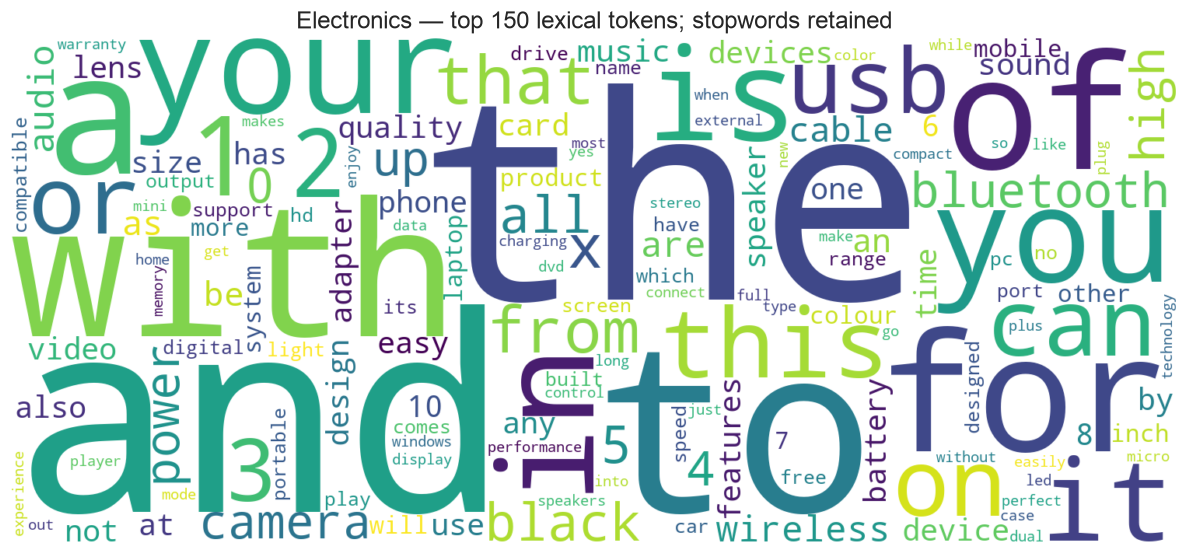

rank,token,count,pct_class_tokens
1,the,45041,3.0062
2,and,41691,2.7826
3,to,30077,2.0075
4,with,25162,1.6794
5,a,20683,1.3805
6,for,19257,1.2853
7,of,18131,1.2101
8,your,15938,1.0638
9,you,15023,1.0027
10,in,14907,0.9950


In [14]:
label='Electronics'
cloud=WordCloud(width=1500,height=650,background_color="white",max_words=150,
                stopwords=set(),collocations=False,normalize_plurals=False,repeat=False,
                random_state=SEED,colormap="viridis").generate_from_frequencies(frequencies[label])
fig,ax=plt.subplots(figsize=(12,5.2))
ax.imshow(cloud,interpolation="bilinear");ax.axis("off")
ax.set_title(f"{label} — top 150 lexical tokens; stopwords retained",fontsize=16)
plt.tight_layout();plt.show()
show_table(top50_tables[label],f"{label}: complete top-50 (count and share of class tokens)",
           collapse=True,index=False,formatters={"pct_class_tokens":lambda x:f"{x:.4f}"})
top=top50_tables[label]
display(prose(f"**Observed:** the leading token is **{top.iloc[0].token}** "
                 f"({int(top.iloc[0]['count']):,} occurrences); the top 50 account for "
                 f"**{top.pct_class_tokens.sum():.2f}%** of this class's lexical occurrences. "
                 "These raw common-word patterns motivate a later stopword ablation, not automatic removal."))

### Type–token ratio and equal-token-budget sensitivity

$TTR=V/T$, where $V$ is the number of distinct lexical types and $T$ is total lexical token
occurrences. Corpus $V$ is the union of class vocabularies, not their sum. Duplicate descriptions
retain their raw occurrence weights in this main analysis. TTR is sensitive to corpus size,
token definition and repetition; a smaller class is not automatically more lexically diverse.

As a simple size-controlled comparison, use $K=\min(100000,\min_c T_c)$ token occurrences per
class. Construct integer type-ID arrays with multiplicities equal to observed frequencies,
then sample **K occurrence positions uniformly without replacement**, independently for 20
repetitions, in the fixed class order above with one NumPy RNG seeded 42. This controls token
budget, not document lengths or duplicate/product dependence. Report mean, sample SD and
range; they describe this sampling procedure and are not confidence intervals for a population.

In [15]:
ttr_rows=[]
for label,counts in [("ALL CORPUS",corpus_frequency),*frequencies.items()]:
    types=len(counts);tokens=sum(counts.values())
    ttr_rows.append({"scope":label,"types_V":types,"occurrences_T":tokens,"TTR_V_over_T":types/tokens})
ttr_table=pd.DataFrame(ttr_rows).set_index("scope")
show_table(ttr_table, "Measured TTR — raw frequency weights",float_format=lambda x:f"{x:.6f}")

TOKEN_BUDGET=min(100000,int(ttr_table.loc[list(LABELS),"occurrences_T"].min()))
REPETITIONS=20
rng=np.random.default_rng(SEED)
budget_records=[]
for label in LABELS:
    counts=np.fromiter(frequencies[label].values(),dtype=np.int64)
    occurrence_type_ids=np.repeat(np.arange(len(counts),dtype=np.int32),counts)
    for repetition in range(REPETITIONS):
        positions=rng.choice(len(occurrence_type_ids),size=TOKEN_BUDGET,replace=False)
        observed_types=np.unique(occurrence_type_ids[positions]).size
        budget_records.append({"label":label,"repetition":repetition+1,"K_tokens":TOKEN_BUDGET,
                               "types_V":observed_types,"TTR":observed_types/TOKEN_BUDGET})
    del occurrence_type_ids
budget_samples=pd.DataFrame(budget_records)
budget_summary=budget_samples.groupby("label").agg(
    repetitions=("TTR","size"),K_tokens=("K_tokens","first"),mean_types=("types_V","mean"),
    mean_TTR=("TTR","mean"),sd_TTR=("TTR","std"),min_TTR=("TTR","min"),max_TTR=("TTR","max")).reindex(LABELS)
show_table(budget_summary.round(6),"Same-budget token sampling: seed 42")
show_table(budget_samples,"All 80 reproducible sampling outcomes",collapse=True,index=False,
           float_format=lambda x:f"{x:.6f}")
raw_class_ttr=ttr_table.loc[list(LABELS),"TTR_V_over_T"]
display(prose(f"**Observed:** the corpus has **{int(ttr_table.loc['ALL CORPUS','types_V']):,}** types "
                 f"in **{int(ttr_table.loc['ALL CORPUS','occurrences_T']):,}** occurrences "
                 f"(TTR **{ttr_table.loc['ALL CORPUS','TTR_V_over_T']:.5f}**). "
                 f"Raw class TTR is highest for **{raw_class_ttr.idxmax()}**; at the shared "
                 f"**{TOKEN_BUDGET:,}**-token budget the highest mean is **{budget_summary.mean_TTR.idxmax()}** "
                 f"(**{budget_summary.mean_TTR.max():.4f}**), compared with the lowest "
                 f"**{budget_summary.mean_TTR.min():.4f}**. This is a controlled descriptive comparison "
                 "under occurrence sampling; it does not establish intrinsic language richness or a best tokenizer."))

,types_V,occurrences_T,TTR_V_over_T
scope,,,
ALL CORPUS,81531,5918452,0.013776
Household,34637,2141070,0.016177
Books,41834,1633793,0.025605
Clothing & Accessories,14697,645326,0.022775
Electronics,29494,1498263,0.019685


,repetitions,K_tokens,mean_types,mean_TTR,sd_TTR,min_TTR,max_TTR
label,,,,,,,
Household,20,100000,10978.20,0.109782,0.000534,0.10857,0.11051
Books,20,100000,13820.80,0.138208,0.000796,0.13680,0.13980
Clothing & Accessories,20,100000,7646.15,0.076462,0.000389,0.07588,0.07743
Electronics,20,100000,10680.00,0.106800,0.000599,0.10542,0.10768


label,repetition,K_tokens,types_V,TTR
Household,1,100000,10997,0.109970
Household,2,100000,10991,0.109910
Household,3,100000,11007,0.110070
Household,4,100000,10958,0.109580
Household,5,100000,10892,0.108920
Household,6,100000,10888,0.108880
Household,7,100000,11010,0.110100
Household,8,100000,10945,0.109450
Household,9,100000,11051,0.110510
Household,10,100000,10857,0.108570


### Zipf rank–frequency analysis

Within each scope, sort frequency descending, break ties alphabetically, and assign one
integer rank per type (no averaged ranks). The tie order does not change the frequency curve.
Plot every observed rank on logarithmic x/y axes. Corpus and class curves use their own ranks;
raw frequencies also reflect different class token totals.

For a reproducible descriptive fit, regress $\log_{10}(f_r)$ on $\log_{10}(r)$ over
**ranks 10 through min(10,000, V)**, inclusive, using ordinary least squares. Report slope and
$R^2$, with a slope −1 reference anchored at rank 10 on the corpus curve. The fit interval
excludes the highest-frequency head and much of the rare tail, so it does not describe every
rank equally. A high $R^2$ on this interval does **not prove a power-law generative model**;
no regression p-value is used to “verify Zipf”.

,vocabulary_V,tokens_T,singleton_types,singleton_pct_types,singleton_pct_occurrences,fit_rank_start,fit_rank_end,slope,intercept,R_squared
scope,,,,,,,,,,
ALL CORPUS,81531,5918452,18198,22.32034,0.30748,10,10000,-1.17265,6.39561,0.97718
Household,34637,2141070,6579,18.99414,0.30728,10,10000,-1.30942,6.36687,0.97279
Books,41834,1633793,8802,21.04030,0.53875,10,10000,-1.14560,5.71340,0.98471
Clothing & Accessories,14697,645326,4078,27.74716,0.63193,10,10000,-1.51047,6.40861,0.96815
Electronics,29494,1498263,6568,22.26894,0.43837,10,10000,-1.32674,6.25886,0.97809


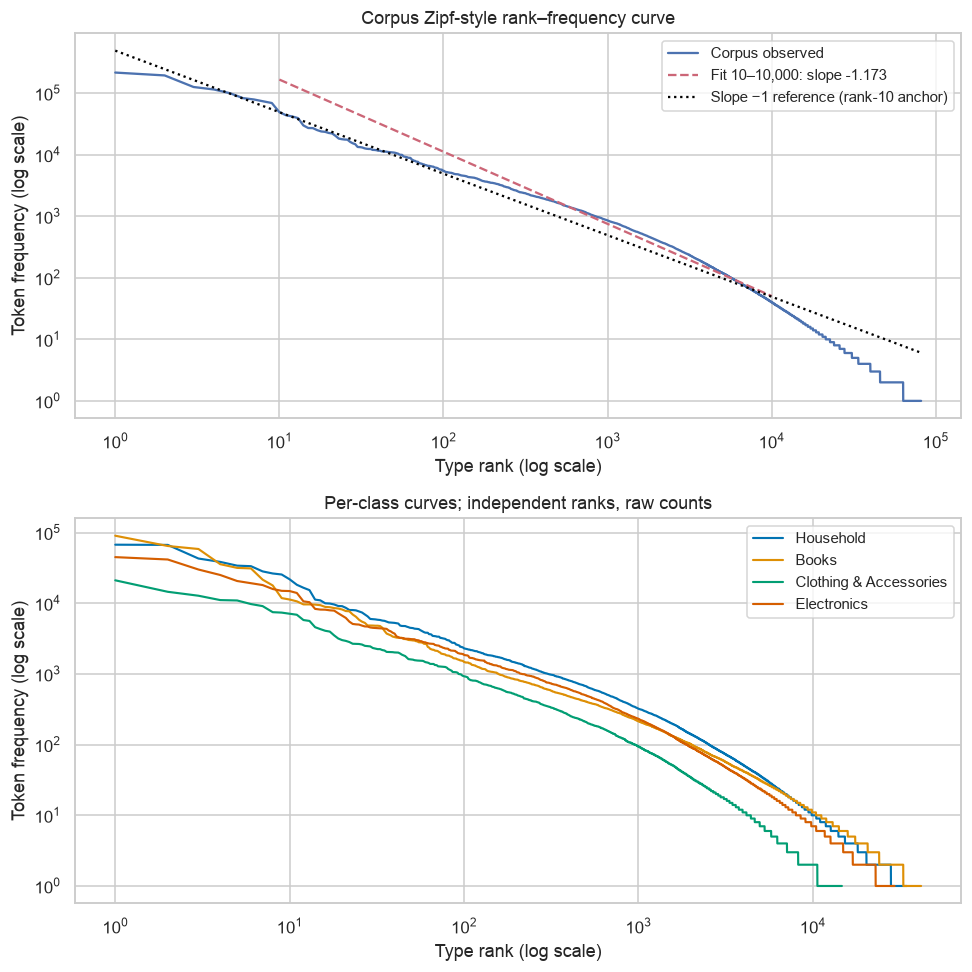

In [16]:
zipf_rows=[]
rank_arrays={}
for label,counts in [("ALL CORPUS",corpus_frequency),*frequencies.items()]:
    f=np.array(list(counts.values()),dtype=np.int64)
    r=np.arange(1,len(f)+1)
    lower,upper=10,min(10000,len(f))
    selected=(r>=lower)&(r<=upper)
    fit=stats.linregress(np.log10(r[selected]),np.log10(f[selected]))
    zipf_rows.append({"scope":label,"vocabulary_V":len(f),"tokens_T":int(f.sum()),
                      "singleton_types":int((f==1).sum()),"singleton_pct_types":100*(f==1).mean(),
                      "singleton_pct_occurrences":100*(f==1).sum()/f.sum(),
                      "fit_rank_start":lower,"fit_rank_end":upper,"slope":fit.slope,
                      "intercept":fit.intercept,"R_squared":fit.rvalue**2})
    rank_arrays[label]=(r,f)
zipf_table=pd.DataFrame(zipf_rows).set_index("scope")
show_table(zipf_table.round(5),"Rank definitions, vocabulary, rare tail and descriptive fit")
fig,axes=plt.subplots(2,1,figsize=(9,9))
r,f=rank_arrays["ALL CORPUS"]
axes[0].loglog(r,f,label="Corpus observed",linewidth=1.5)
record=zipf_table.loc["ALL CORPUS"]
fit_r=np.arange(int(record.fit_rank_start),int(record.fit_rank_end)+1)
axes[0].loglog(fit_r,10**record.intercept*fit_r**record.slope,"--",color="#CC6677",
               label=f"Fit 10–{int(record.fit_rank_end):,}: slope {record.slope:.3f}")
axes[0].loglog(r,f[9]*10/r,":",color="black",label="Slope −1 reference (rank-10 anchor)")
for label in LABELS:
    cr,cf=rank_arrays[label]
    axes[1].loglog(cr,cf,label=label,color=COLORS[label],linewidth=1.4)
for ax in axes:
    ax.set(xlabel="Type rank (log scale)",ylabel="Token frequency (log scale)")
    ax.legend(fontsize=10)
axes[0].set_title("Corpus Zipf-style rank–frequency curve")
axes[1].set_title("Per-class curves; independent ranks, raw counts")
plt.tight_layout();plt.show()
corpus_zipf=zipf_table.loc["ALL CORPUS"]
display(prose(f"**Observed:** corpus fit slope = **{corpus_zipf.slope:.3f}**, "
                 f"R² = **{corpus_zipf.R_squared:.4f}** on ranks "
                 f"{int(corpus_zipf.fit_rank_start)}–{int(corpus_zipf.fit_rank_end):,}. "
                 f"Singletons comprise **{corpus_zipf.singleton_pct_types:.2f}%** of lexical types "
                 f"but **{corpus_zipf.singleton_pct_occurrences:.3f}%** of occurrences. "
                 "The frequent head and long rare tail are compatible with Zipf-like behavior; deviations "
                 "and the selected interval prevent a universal power-law claim. Rare codes, spellings and "
                 "numeric fragments can enlarge later sparse matrices and create OOV types in internal "
                 "assessment. Vocabulary filtering/subwords require later train-only measurement."))

## Discussion

The whole-corpus audit reveals repeated listings and product variants, unequal class support,
long descriptions, and a sparse lexical tail. These observations lead to **questions for later
controlled comparisons**, not a claim that a particular preprocessing method is best.

Length effects must be read with their magnitude: large N and repeated templates can give
very small p-values. Deduplication changes both the estimand (one listing text rather than
one row) and the apparent class mix. Even the sensitivity view may contain related products;
Holm adjustment addresses multiple comparisons, not dependence.

The top-50 tables intentionally retain function words. A later stopword comparison must measure
label information and downstream performance. Likewise, punctuation and digits can encode sizes,
units, model identifiers and version numbers. A blanket removal rule would need evidence.
Corpus-size-controlled TTR reduces one known confounder but retains repetition and token-definition
sensitivity. Zipf fits summarize only the declared rank interval.

The table below links each measured finding to its next-stage implication. No train/test split,
learned vocabulary, normalized corpus export or classifier is created in this stage.

In [17]:
findings=pd.DataFrame([
    {"Finding":"Missing input, otherwise valid labels",
     "Evidence":f"{int(text_missing.sum())} missing text; {int(text_blank.sum())} blank; "
                f"{int(label_missing.sum())} missing / {int(label_invalid.sum())} invalid labels; main N={len(analysis):,}",
     "Implication for next preprocessing stage":"Declare exclusion policy; preserve source row indices and raw strings."},
    {"Finding":"Repeated listings and related variants threaten leakage",
     "Evidence":f"Exact redundant rows={int(duplicate_audit.iloc[0].redundant_rows):,} "
                f"({duplicate_audit.iloc[0].redundant_pct_main:.2f}%); canonical extra={int(duplicate_audit.iloc[1].redundant_rows-duplicate_audit.iloc[0].redundant_rows)}; "
                f"{len(near_examples)} high-overlap examples / {near_candidate_n} biased candidate pairs",
     "Implication for next preprocessing stage":"Freeze exact/canonical grouping before later splits; inspect product variants and cross-partition matches; no claim of complete deduplication."},
    {"Finding":"Unequal class support",
     "Evidence":f"Raw largest/smallest={imbalance_ratio:.2f}×; exact-unique={unique_imbalance_ratio:.2f}×",
     "Implication for next preprocessing stage":"Report per-class and macro metrics later; compare original-prevalence assessment before choosing any resampling."},
    {"Finding":"Length distributions differ with a pronounced right tail",
     "Evidence":f"Median word range={medians.min():.0f}–{medians.max():.0f}; P95={long_tail.word_P95:.0f}; max={long_tail.word_max:,.0f}; "
                f">512 whitespace words={int(long_tail.texts_above_512_whitespace_words):,} "
                f"({long_tail.pct_above_512_whitespace_words:.2f}%); Holm rejections={int(mw_main.reject_Holm.sum())}/12",
     "Implication for next preprocessing stage":"Measure actual model/subword lengths before selecting Sentence Transformer truncation/chunking; retain tails in reporting."},
    {"Finding":"Numbers and surface syntax need contextual review",
     "Evidence":f"Digits in {pattern_flags['digit'].mean():.2%} of texts; tag/entity/URL/mention/hashtag matches="
                + '/'.join(str(int(pattern_counts[n])) for n in special_names),
     "Implication for next preprocessing stage":"Inspect quantities, units and model codes; compare each cleaning step with measured changes. Rare pattern matches need no blanket deletion rule."},
    {"Finding":"Common lexical head includes function words",
     "Evidence":"; ".join(f"{label}: {top50_tables[label].iloc[0].token}, top-50 share={top50_tables[label].pct_class_tokens.sum():.1f}%" for label in LABELS),
     "Implication for next preprocessing stage":"Retain a no-stopword-removal baseline; later measure vocabulary, information and classifier effects."},
    {"Finding":"TTR depends on corpus size and sampling",
     "Evidence":f"Corpus V/T={int(corpus_zipf.vocabulary_V):,}/{int(corpus_zipf.tokens_T):,}; "
                f"shared K={TOKEN_BUDGET:,}, mean class TTR range={budget_summary.mean_TTR.min():.4f}–{budget_summary.mean_TTR.max():.4f}",
     "Implication for next preprocessing stage":"Use the same token definition and token budgets; do not equate raw TTR with intrinsic diversity."},
    {"Finding":"Long rare lexical tail",
     "Evidence":f"Singleton types={int(corpus_zipf.singleton_types):,} ({corpus_zipf.singleton_pct_types:.2f}%); "
                f"rank {int(corpus_zipf.fit_rank_start)}–{int(corpus_zipf.fit_rank_end):,} slope={corpus_zipf.slope:.3f}, R²={corpus_zipf.R_squared:.4f}",
     "Implication for next preprocessing stage":"Evaluate vocabulary fragmentation, sparsity and OOV later using training-only fitting; a high R² does not prove a power law."},
    {"Finding":"Full-corpus EDA exposure",
     "Evidence":f"All {len(raw):,} rows/labels available for audit; no split exported",
     "Implication for next preprocessing stage":"Document a future internal post-EDA assessment; use independent data for any external-test claim."},
])
show_table(findings,index=False)

Finding,Evidence,Implication for next preprocessing stage
"Missing input, otherwise valid labels","1 missing text; 0 blank; 0 missing / 0 invalid labels; main N=50,424",Declare exclusion policy; preserve source row indices and raw strings.
Repeated listings and related variants threaten leakage,"Exact redundant rows=22,622 (44.86%); canonical extra=50; 210 high-overlap examples / 500 biased candidate pairs",Freeze exact/canonical grouping before later splits; inspect product variants and cross-partition matches; no claim of complete deduplication.
Unequal class support,Raw largest/smallest=2.23×; exact-unique=1.99×,Report per-class and macro metrics later; compare original-prevalence assessment before choosing any resampling.
Length distributions differ with a pronounced right tail,"Median word range=56–99; P95=311; max=8,181; >512 whitespace words=759 (1.51%); Holm rejections=12/12",Measure actual model/subword lengths before selecting Sentence Transformer truncation/chunking; retain tails in reporting.
Numbers and surface syntax need contextual review,Digits in 78.19% of texts; tag/entity/URL/mention/hashtag matches=36/53/328/152/335,"Inspect quantities, units and model codes; compare each cleaning step with measured changes. Rare pattern matches need no blanket deletion rule."
Common lexical head includes function words,"Household: and, top-50 share=31.9%; Books: the, top-50 share=36.7%; Clothing & Accessories: and, top-50 share=34.4%; Electronics: the, top-50 share=30.7%","Retain a no-stopword-removal baseline; later measure vocabulary, information and classifier effects."
TTR depends on corpus size and sampling,"Corpus V/T=81,531/5,918,452; shared K=100,000, mean class TTR range=0.0765–0.1382",Use the same token definition and token budgets; do not equate raw TTR with intrinsic diversity.
Long rare lexical tail,"Singleton types=18,198 (22.32%); rank 10–10,000 slope=-1.173, R²=0.9772","Evaluate vocabulary fragmentation, sparsity and OOV later using training-only fitting; a high R² does not prove a power law."
Full-corpus EDA exposure,"All 50,425 rows/labels available for audit; no split exported",Document a future internal post-EDA assessment; use independent data for any external-test claim.


## Conclusion

Stage 01 provides the source audit and required Text EDA: class length summaries/distributions,
all pairwise Mann–Whitney results with multiplicity/effect-size/sensitivity reporting, four
word clouds and complete class top-50 tables, corpus/class/equal-budget TTR, and corpus/class
Zipf diagnostics. The evidence supports controlled preprocessing experiments with explicit
leakage and exposure boundaries, rather than an untested “best cleaning” prescription.

Next is **Stage 02 — Normalization and tokenization**: define the handling of missing text
and product groups, compare individual normalization operations, then compare the required
word/sentence/character/BPE tokenization strategies with train-only vocabulary and OOV reporting.
Stages 03–04 will cover stopwords/morphology and representations. Those chapters are planned,
not implemented; see the [Part B roadmap](index.md). Part B and the whole assignment remain incomplete.

In [18]:
pd.testing.assert_frame_equal(raw,raw_snapshot)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==raw_sha256_before,"Raw CSV changed"
assert len(mw_main)==len(mw_unique)==12
assert all(len(table)==50 for table in top50_tables.values())
assert set(frequencies)==set(LABELS)
assert all(sum(counts.values())>0 for counts in frequencies.values())
print("Read-only integrity verified; raw frame and CSV unchanged.")
print("Stage 01 saved evidence: four word clouds, four complete top-50 tables, 12+12 pairwise tests, TTR and Zipf.")

Read-only integrity verified; raw frame and CSV unchanged.
Stage 01 saved evidence: four word clouds, four complete top-50 tables, 12+12 pairwise tests, TTR and Zipf.
